In [2]:
import pandas as pd
import seaborn as sns
import numpy as np

In [3]:
df = sns.load_dataset('iris')

In [4]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [5]:
from sklearn.preprocessing import LabelEncoder
encode = LabelEncoder()
df['species'] = encode.fit_transform(df['species'])

In [6]:
df.sample(5)

,sepal_length,sepal_width,petal_length,petal_width,species
111,6.4,2.7,5.3,1.9,2
142,5.8,2.7,5.1,1.9,2
42,4.4,3.2,1.3,0.2,0
71,6.1,2.8,4.0,1.3,1
131,7.9,3.8,6.4,2.0,2


In [7]:
df = df[['sepal_length','petal_length','species']]

In [8]:
x = df.drop(columns=['species'])
y = df['species']

In [9]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=2)

In [10]:
from sklearn.linear_model import LogisticRegression
log = LogisticRegression()

In [11]:
log.fit(x_train,y_train)
y_pred = log.predict(x_test)

In [12]:
from sklearn.metrics import confusion_matrix,classification_report
confusion_matrix(y_test,y_pred)

array([[14,  0,  0],
       [ 0,  7,  1],
       [ 0,  0,  8]])

In [13]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      0.88      0.93         8
           2       0.89      1.00      0.94         8

    accuracy                           0.97        30
   macro avg       0.96      0.96      0.96        30
weighted avg       0.97      0.97      0.97        30



In [14]:
query = np.array([[3.4,2.7]])
log.predict_proba(query)

C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([[7.25865651e-01, 2.73720718e-01, 4.13631316e-04]])

In [15]:
from mlxtend.plotting import plot_decision_regions
import matplotlib.pyplot as plt

C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


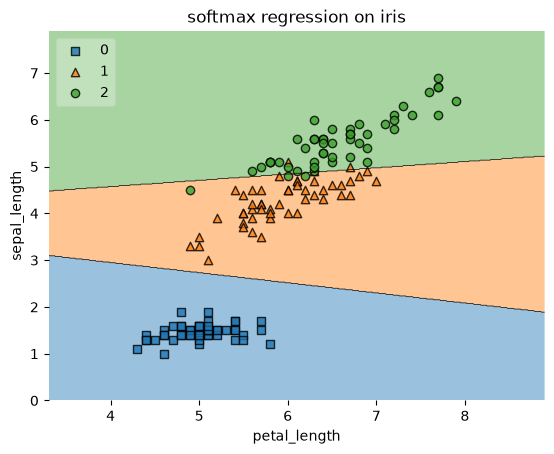

In [16]:
plot_decision_regions(x.values, y.values, log, legend=2)

plt.xlabel('petal_length')
plt.ylabel('sepal_length')
plt.title('softmax regression on iris')
plt.show()